In [1]:
# STEP 1: IMPORTS AND CONFIGURATION

import os
import json
from datasets import load_dataset
from PIL import Image
from collections import defaultdict
from tqdm import tqdm
import random

# Final 25 COCO classes
# Couch (COCO ID 57) removed
SELECTED_CLASSES = {
    'person': 0,
    'bicycle': 1,
    'car': 2,
    'motorcycle': 3,
    'airplane': 4,
    'bus': 5,
    'train': 6,
    'truck': 7,
    'traffic light': 9,
    'stop sign': 11,
    'bench': 13,
    'bird': 14,
    'cat': 15,
    'dog': 16,
    'horse': 17,
    'cow': 19,
    'elephant': 20,
    'bottle': 39,
    'cup': 41,
    'bowl': 45,
    'pizza': 53,
    'cake': 55,
    'chair': 56,
    'potted plant': 58,
    'bed': 59
}

IMAGES_PER_CLASS = 100

# Keep the new dataset separate from our old datasets
BASE_DIR = r"E:\SmartVision-AI\data\final_dataset"

print("Number of classes:", len(SELECTED_CLASSES))
print("Images per class:", IMAGES_PER_CLASS)
print("Target total:", len(SELECTED_CLASSES) * IMAGES_PER_CLASS)
print("Dataset directory:", BASE_DIR)

Number of classes: 25
Images per class: 100
Target total: 2500
Dataset directory: E:\SmartVision-AI\data\final_dataset


In [2]:
# STEP 2: LOAD COCO DATASET FROM HUGGING FACE

print("📥 Loading COCO dataset in STREAMING mode (no full download)...")

dataset = load_dataset(
    "detection-datasets/coco",
    split="train",
    streaming=True
)

print("✅ Dataset loaded in streaming mode!")

📥 Loading COCO dataset in STREAMING mode (no full download)...


Resolving data files:   0%|          | 0/40 [00:00<?, ?it/s]

✅ Dataset loaded in streaming mode!


In [3]:
# STEP 3 - CORRECTED: COLLECT CANDIDATES USING XYXY BOUNDING BOXES

print("🔄 Reloading COCO stream...")

dataset = load_dataset(
    "detection-datasets/coco",
    split="train",
    streaming=True
)

print("✅ Stream reloaded")
print()

CANDIDATES_PER_CLASS = 250
MAX_ITERATIONS = 60000

id_to_class = {
    class_id: class_name
    for class_name, class_id in SELECTED_CLASSES.items()
}

class_candidates = {
    class_name: []
    for class_name in SELECTED_CLASSES
}

images_processed = 0

print("=" * 70)
print("🔍 COLLECTING CANDIDATES WITH CORRECT XYXY BBOX FORMAT")
print("=" * 70)

for item in dataset:

    images_processed += 1

    img = item["image"]
    img_width, img_height = img.size
    image_area = img_width * img_height

    annotations = item["objects"]
    bboxes = annotations["bbox"]
    categories = annotations["category"]

    for bbox, cat_id in zip(bboxes, categories):

        if cat_id not in id_to_class:
            continue

        class_name = id_to_class[cat_id]

        if len(class_candidates[class_name]) >= CANDIDATES_PER_CLASS:
            continue

        # Hugging Face COCO bbox format:
        # [x_min, y_min, x_max, y_max]
        x1, y1, x2, y2 = bbox

        # Clamp coordinates to image boundaries
        x1 = max(0, min(x1, img_width))
        y1 = max(0, min(y1, img_height))
        x2 = max(0, min(x2, img_width))
        y2 = max(0, min(y2, img_height))

        bbox_width = x2 - x1
        bbox_height = y2 - y1

        # Reject invalid boxes
        if bbox_width <= 0 or bbox_height <= 0:
            continue

        bbox_area = bbox_width * bbox_height
        area_ratio = bbox_area / image_area

        # Mild initial filter only
        if area_ratio < 0.01:
            continue

        class_candidates[class_name].append({
            "image": img.copy(),
            "annotations": annotations,
            "bbox": [x1, y1, x2, y2],
            "class_name": class_name,
            "class_id": cat_id,
            "source_idx": images_processed,
            "image_width": img_width,
            "image_height": img_height,
            "bbox_width": bbox_width,
            "bbox_height": bbox_height,
            "bbox_area": bbox_area,
            "area_ratio": area_ratio
        })

    if images_processed % 1000 == 0:

        completed = sum(
            len(v) >= CANDIDATES_PER_CLASS
            for v in class_candidates.values()
        )

        print(
            f"Processed {images_processed:5d} images | "
            f"Classes complete: {completed}/"
            f"{len(SELECTED_CLASSES)}"
        )

    if all(
        len(v) >= CANDIDATES_PER_CLASS
        for v in class_candidates.values()
    ):
        print("\n🎉 Candidate pool complete!")
        break

    if images_processed >= MAX_ITERATIONS:
        print("\n⚠️ Maximum iteration limit reached.")
        break


print("\n" + "=" * 70)
print("📊 CORRECTED CANDIDATE COLLECTION RESULTS")
print("=" * 70)

for class_name in SELECTED_CLASSES:

    count = len(class_candidates[class_name])

    status = (
        "✅"
        if count >= CANDIDATES_PER_CLASS
        else "⚠️"
    )

    print(
        f"{status} {class_name:20s}: "
        f"{count:3d}/{CANDIDATES_PER_CLASS}"
    )

print("=" * 70)
print("Images processed:", images_processed)

🔄 Reloading COCO stream...


Resolving data files:   0%|          | 0/40 [00:00<?, ?it/s]

✅ Stream reloaded

🔍 COLLECTING CANDIDATES WITH CORRECT XYXY BBOX FORMAT
Processed  1000 images | Classes complete: 1/25
Processed  2000 images | Classes complete: 2/25
Processed 11000 images | Classes complete: 23/25
Processed 12000 images | Classes complete: 23/25
Processed 13000 images | Classes complete: 23/25
Processed 14000 images | Classes complete: 23/25
Processed 15000 images | Classes complete: 23/25
Processed 16000 images | Classes complete: 23/25
Processed 17000 images | Classes complete: 23/25
Processed 18000 images | Classes complete: 23/25
Processed 19000 images | Classes complete: 24/25
Processed 20000 images | Classes complete: 24/25
Processed 21000 images | Classes complete: 24/25
Processed 22000 images | Classes complete: 24/25
Processed 23000 images | Classes complete: 24/25
Processed 24000 images | Classes complete: 24/25

🎉 Candidate pool complete!

📊 CORRECTED CANDIDATE COLLECTION RESULTS
✅ person              : 250/250
✅ bicycle             : 250/250
✅ car      

In [4]:
# STEP 4 - CORRECTED: ANALYZE TRUE BOUNDING BOX AREAS

import numpy as np

print("=" * 88)
print("📊 CORRECTED CANDIDATE BOUNDING BOX ANALYSIS")
print("=" * 88)

print(
    f"{'Class':20s} "
    f"{'Min %':>8s} "
    f"{'25%':>8s} "
    f"{'Median':>8s} "
    f"{'Mean':>8s} "
    f"{'75%':>8s} "
    f"{'Max %':>8s}"
)

print("-" * 88)

for class_name in SELECTED_CLASSES:

    ratios = np.array([
        item["area_ratio"] * 100
        for item in class_candidates[class_name]
    ])

    print(
        f"{class_name:20s} "
        f"{ratios.min():8.2f} "
        f"{np.percentile(ratios, 25):8.2f} "
        f"{np.median(ratios):8.2f} "
        f"{ratios.mean():8.2f} "
        f"{np.percentile(ratios, 75):8.2f} "
        f"{ratios.max():8.2f}"
    )

print("=" * 88)

📊 CORRECTED CANDIDATE BOUNDING BOX ANALYSIS
Class                   Min %      25%   Median     Mean      75%    Max %
----------------------------------------------------------------------------------------
person                   1.01     2.47     7.11    15.16    18.22    96.10
bicycle                  1.00     1.96     3.50     9.34     9.85    76.05
car                      1.01     1.49     2.99     7.81     6.59    97.98
motorcycle               1.00     2.91     9.03    19.35    30.32    98.65
airplane                 1.01     4.83    16.03    23.34    36.64    98.21
bus                      1.01     5.05    17.05    25.11    42.21    96.91
train                    1.07     8.84    21.03    26.78    38.05    98.70
truck                    1.01     2.00     4.68    14.86    18.21    95.95
traffic light            1.01     1.42     2.29     4.04     4.15    33.47
stop sign                1.01     3.13     7.85    14.48    20.74    86.04
bench                    1.01     1.87    

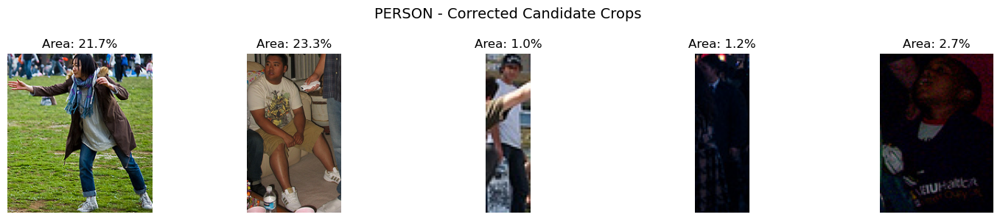

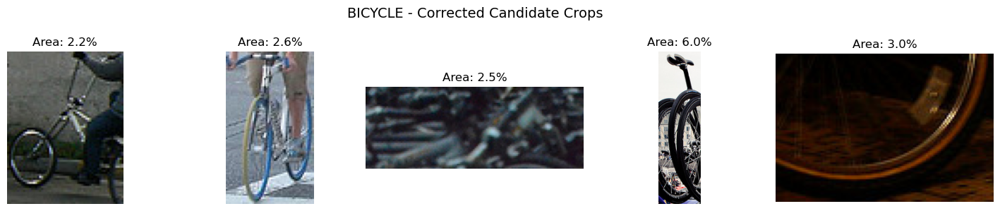

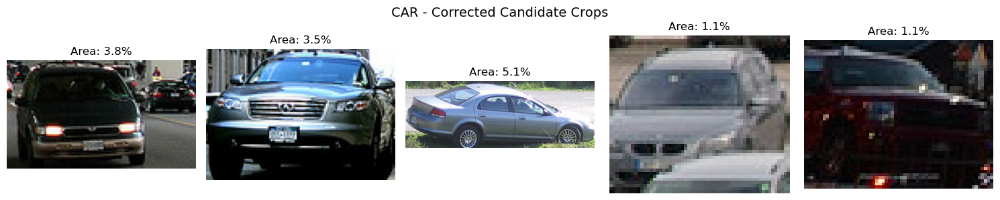

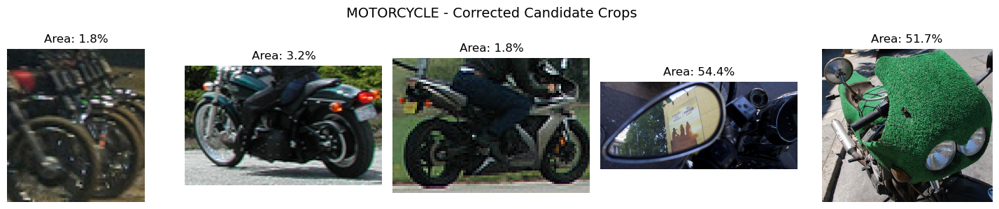

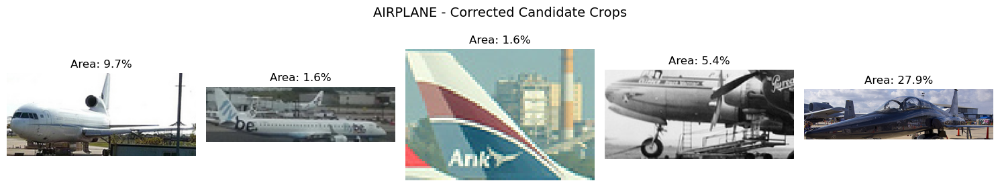

...

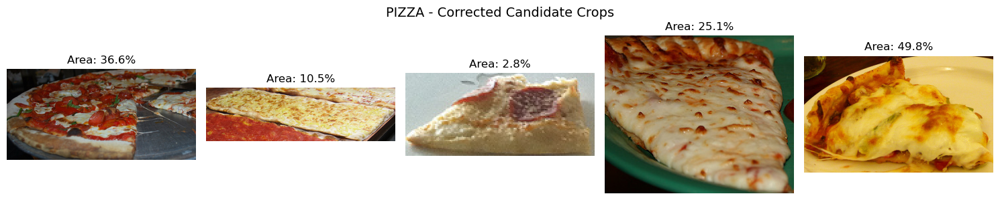

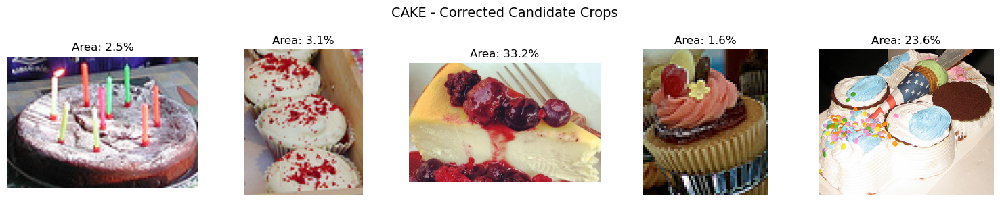

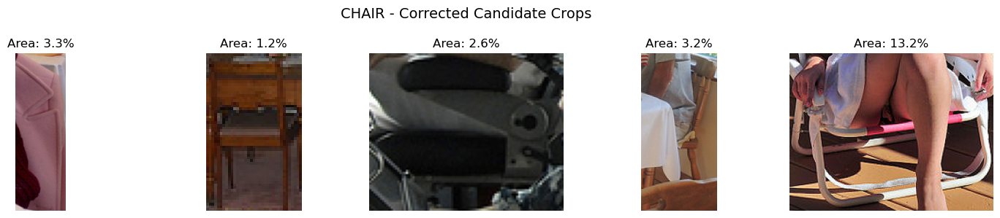

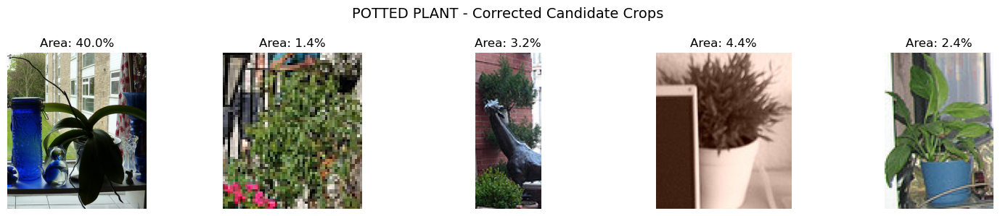

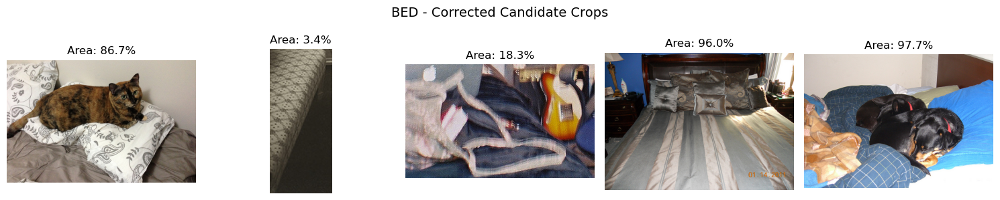

In [5]:
# STEP 5 - CORRECTED: VISUAL INSPECTION OF XYXY CROPS

import matplotlib.pyplot as plt
import random

random.seed(42)

SAMPLES_PER_CLASS = 5

for class_name in SELECTED_CLASSES:

    candidates = class_candidates[class_name]

    samples = random.sample(
        candidates,
        min(SAMPLES_PER_CLASS, len(candidates))
    )

    fig, axes = plt.subplots(
        1,
        SAMPLES_PER_CLASS,
        figsize=(15, 3)
    )

    fig.suptitle(
        f"{class_name.upper()} - Corrected Candidate Crops",
        fontsize=14
    )

    for ax, item in zip(axes, samples):

        img = item["image"].convert("RGB")

        # CORRECT FORMAT: x1, y1, x2, y2
        x1, y1, x2, y2 = item["bbox"]

        crop = img.crop((
            int(x1),
            int(y1),
            int(x2),
            int(y2)
        ))

        ax.imshow(crop)

        ax.set_title(
            f"Area: {item['area_ratio'] * 100:.1f}%"
        )

        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [6]:
# STEP 6: SCORE AND SELECT FINAL 100 CANDIDATES PER CLASS

import numpy as np
import random

FINAL_IMAGES_PER_CLASS = 100
random.seed(42)

selected_candidates = {}

print("=" * 78)
print("🎯 SELECTING FINAL 100 OBJECTS PER CLASS")
print("=" * 78)

for class_name in SELECTED_CLASSES:

    candidates = class_candidates[class_name]

    # --------------------------------------------------
    # 1. Calculate area distribution for this class
    # --------------------------------------------------
    areas = np.array([
        item["area_ratio"]
        for item in candidates
    ])

    q25 = np.percentile(areas, 25)
    median = np.median(areas)

    # --------------------------------------------------
    # 2. Score each candidate
    # --------------------------------------------------
    scored = []

    for item in candidates:

        area = item["area_ratio"]

        # Relative area score
        # Larger than the class median is good,
        # but extremely large objects don't receive
        # unlimited extra preference.
        area_score = min(
            area / max(median, 1e-8),
            2.0
        )

        # Resolution of actual cropped object
        bw = item["bbox_width"]
        bh = item["bbox_height"]

        min_dimension = min(bw, bh)

        # Prefer objects with enough pixel detail
        resolution_score = min(
            min_dimension / 100.0,
            1.0
        )

        # Avoid extremely thin bounding boxes
        aspect_ratio = max(bw, bh) / max(min(bw, bh), 1)

        if aspect_ratio <= 4:
            aspect_score = 1.0
        elif aspect_ratio <= 6:
            aspect_score = 0.8
        else:
            aspect_score = 0.5

        # Combined quality score
        quality_score = (
            0.60 * area_score +
            0.30 * resolution_score +
            0.10 * aspect_score
        )

        candidate = item.copy()
        candidate["quality_score"] = quality_score

        scored.append(candidate)

    # --------------------------------------------------
    # 3. Remove weakest quarter by object area
    # --------------------------------------------------
    filtered = [
        item for item in scored
        if item["area_ratio"] >= q25
    ]

    # --------------------------------------------------
    # 4. Sort by quality
    # --------------------------------------------------
    filtered.sort(
        key=lambda x: x["quality_score"],
        reverse=True
    )

    # --------------------------------------------------
    # 5. Keep best 100
    # --------------------------------------------------
    selected = filtered[:FINAL_IMAGES_PER_CLASS]

    selected_candidates[class_name] = selected

    selected_areas = np.array([
        item["area_ratio"] * 100
        for item in selected
    ])

    print(
        f"✅ {class_name:20s} "
        f"selected={len(selected):3d} | "
        f"area {selected_areas.min():5.2f}% - "
        f"{selected_areas.max():5.2f}% | "
        f"median={np.median(selected_areas):5.2f}%"
    )

print("=" * 78)

total_selected = sum(
    len(items)
    for items in selected_candidates.values()
)

print("Total selected:", total_selected)

🎯 SELECTING FINAL 100 OBJECTS PER CLASS
✅ person               selected=100 | area  9.70% - 96.10% | median=22.11%
✅ bicycle              selected=100 | area  5.11% - 76.05% | median=14.08%
✅ car                  selected=100 | area  3.75% - 97.98% | median= 8.40%
✅ motorcycle           selected=100 | area 14.19% - 98.65% | median=35.48%
✅ airplane             selected=100 | area 23.93% - 98.21% | median=40.98%
✅ bus                  selected=100 | area 30.40% - 96.91% | median=45.92%
✅ train                selected=100 | area 27.29% - 98.70% | median=45.23%
✅ truck                selected=100 | area  8.20% - 95.95% | median=22.17%
✅ traffic light        selected=100 | area  2.79% - 33.47% | median= 5.18%
✅ stop sign            selected=100 | area 11.44% - 86.04% | median=25.13%
✅ bench                selected=100 | area  7.23% - 99.88% | median=22.27%
✅ bird                 selected=100 | area 10.41% - 98.77% | median=21.69%
✅ cat                  selected=100 | area 31.31% - 98.50% |

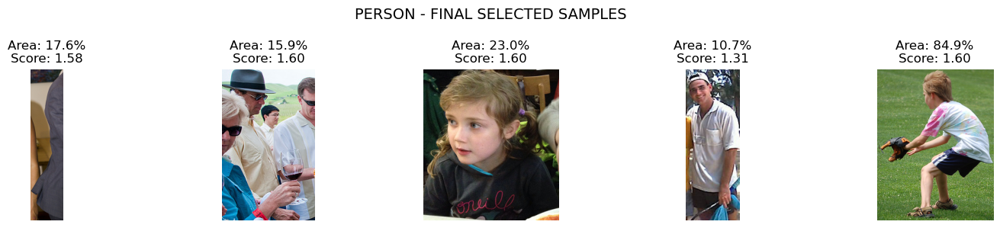

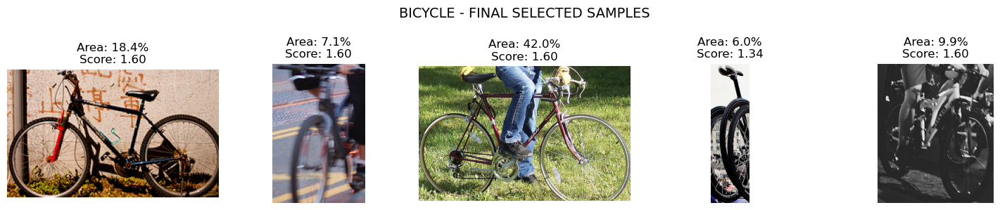

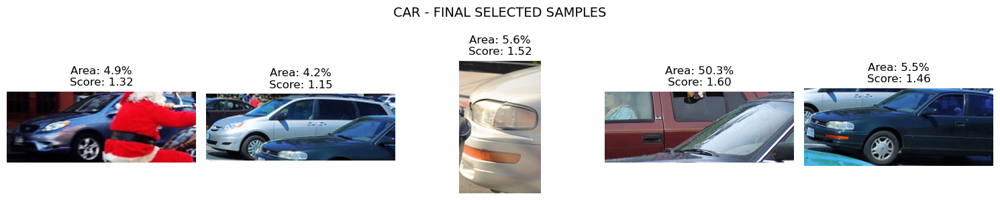

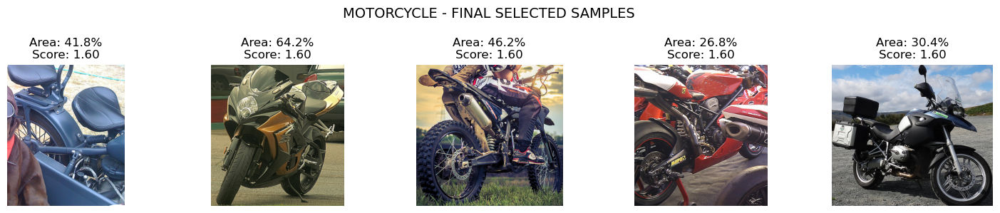

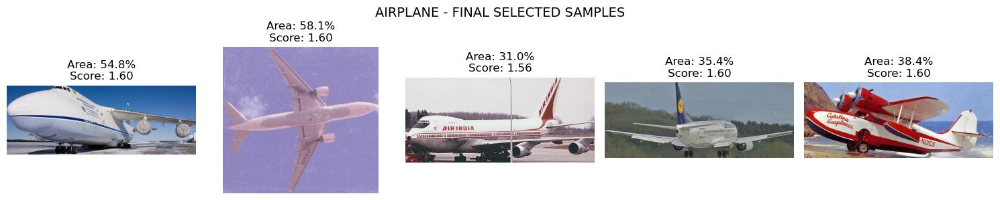

...

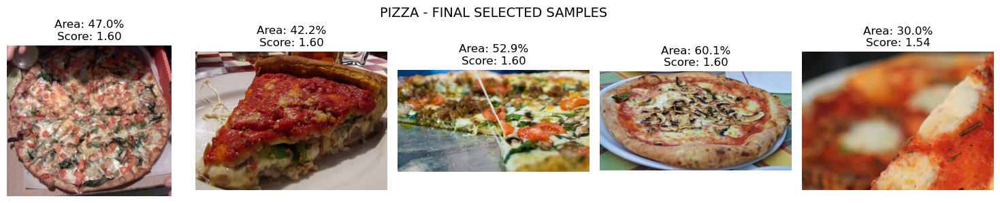

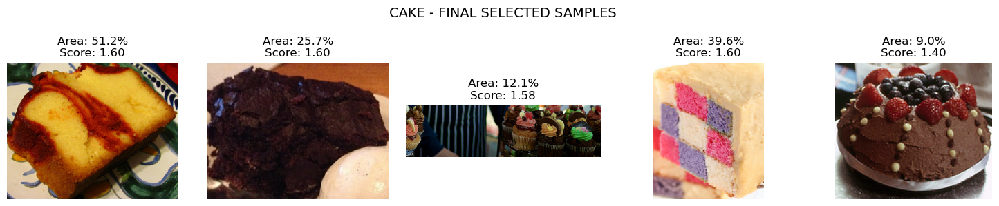

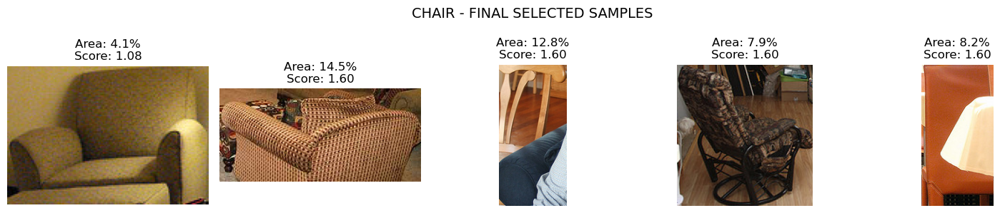

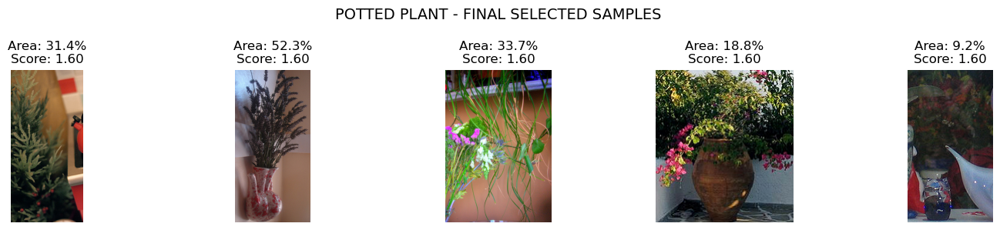

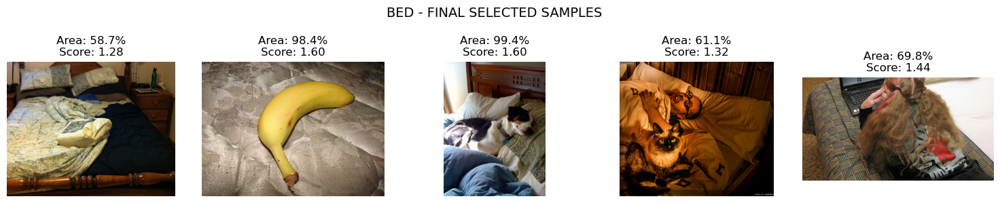

In [7]:
# STEP 7: VISUAL INSPECTION OF FINAL SELECTED DATASET

import matplotlib.pyplot as plt
import random

random.seed(42)

SAMPLES_PER_CLASS = 5

for class_name in SELECTED_CLASSES:

    selected = selected_candidates[class_name]

    samples = random.sample(
        selected,
        min(SAMPLES_PER_CLASS, len(selected))
    )

    fig, axes = plt.subplots(
        1,
        SAMPLES_PER_CLASS,
        figsize=(15, 3)
    )

    fig.suptitle(
        f"{class_name.upper()} - FINAL SELECTED SAMPLES",
        fontsize=14
    )

    for ax, item in zip(axes, samples):

        img = item["image"].convert("RGB")

        x1, y1, x2, y2 = item["bbox"]

        crop = img.crop((
            int(x1),
            int(y1),
            int(x2),
            int(y2)
        ))

        ax.imshow(crop)

        ax.set_title(
            f"Area: {item['area_ratio'] * 100:.1f}%\n"
            f"Score: {item['quality_score']:.2f}"
        )

        ax.axis("off")

    plt.tight_layout()
    plt.show()

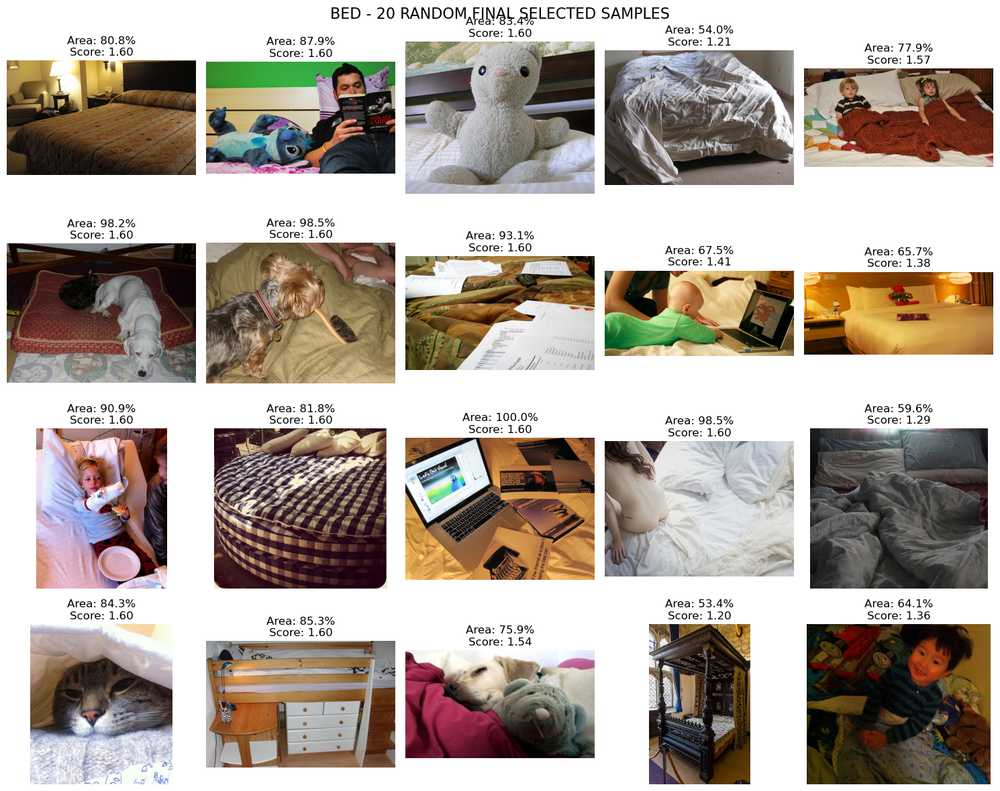

In [8]:
# STEP 7A: DEEP CHECK OF BED CLASS

import matplotlib.pyplot as plt
import random

random.seed(123)

class_name = "bed"
selected = selected_candidates[class_name]

samples = random.sample(selected, 20)

fig, axes = plt.subplots(4, 5, figsize=(15, 12))

fig.suptitle(
    "BED - 20 RANDOM FINAL SELECTED SAMPLES",
    fontsize=16
)

for ax, item in zip(axes.flatten(), samples):

    img = item["image"].convert("RGB")

    x1, y1, x2, y2 = item["bbox"]

    crop = img.crop((
        int(x1),
        int(y1),
        int(x2),
        int(y2)
    ))

    ax.imshow(crop)

    ax.set_title(
        f"Area: {item['area_ratio'] * 100:.1f}%\n"
        f"Score: {item['quality_score']:.2f}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()


In [9]:
# STEP 7B: ANALYZE COMPETING OBJECTS INSIDE TARGET CROPS

from collections import Counter

id_to_name = {
    class_id: class_name
    for class_name, class_id in SELECTED_CLASSES.items()
}

def intersection_area(box_a, box_b):
    """
    Boxes are XYXY:
    [x1, y1, x2, y2]
    """

    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    ix1 = max(ax1, bx1)
    iy1 = max(ay1, by1)
    ix2 = min(ax2, bx2)
    iy2 = min(ay2, by2)

    iw = max(0, ix2 - ix1)
    ih = max(0, iy2 - iy1)

    return iw * ih


print("=" * 85)
print("🔎 COMPETING OBJECT ANALYSIS")
print("=" * 85)

for class_name in SELECTED_CLASSES:

    target_class_id = SELECTED_CLASSES[class_name]

    affected = 0
    competing_classes = Counter()

    for item in selected_candidates[class_name]:

        target_box = item["bbox"]

        tx1, ty1, tx2, ty2 = target_box
        target_area = max(
            (tx2 - tx1) * (ty2 - ty1),
            1
        )

        annotations = item["annotations"]

        categories = annotations["category"]
        boxes = annotations["bbox"]

        has_competitor = False

        for other_box, other_cat in zip(boxes, categories):

            # Ignore target class itself
            if other_cat == target_class_id:
                continue

            # Only analyze our 25 selected classes
            if other_cat not in id_to_name:
                continue

            # COCO boxes in this dataset are XYXY
            ox1, oy1, ox2, oy2 = other_box

            overlap = intersection_area(
                target_box,
                [ox1, oy1, ox2, oy2]
            )

            overlap_ratio = overlap / target_area

            # Other object occupies at least 15%
            # of the target crop
            if overlap_ratio >= 0.15:

                has_competitor = True
                competing_classes[id_to_name[other_cat]] += 1

        if has_competitor:
            affected += 1

    competitors_text = ", ".join(
        f"{name}:{count}"
        for name, count in competing_classes.most_common(4)
    )

    if not competitors_text:
        competitors_text = "none"

    print(
        f"{class_name:20s} "
        f"affected={affected:3d}/100 | "
        f"{competitors_text}"
    )

print("=" * 85)

🔎 COMPETING OBJECT ANALYSIS
person               affected= 21/100 | bench:5, chair:4, motorcycle:3, truck:2
bicycle              affected= 65/100 | person:54, car:8, motorcycle:7, bus:6
car                  affected= 45/100 | person:32, truck:11, motorcycle:10, cat:2
motorcycle           affected= 50/100 | person:48, car:5, dog:3, bicycle:2
airplane             affected=  4/100 | person:4, car:1
bus                  affected= 16/100 | person:8, car:3, truck:2, train:1
train                affected= 10/100 | person:7, cake:2, bus:1, bicycle:1
truck                affected= 33/100 | person:17, car:13, bus:4, cow:2
traffic light        affected=  5/100 | car:2, person:1, bird:1, stop sign:1
stop sign            affected=  7/100 | person:5, bus:2, truck:1, car:1
bench                affected= 67/100 | person:75, chair:7, cat:4, car:3
bird                 affected= 12/100 | person:11, chair:2, bench:1, cake:1
cat                  affected= 38/100 | person:13, bed:11, chair:8, bench:2
dog   

In [10]:
# STEP 7C: RESELECT USING OBJECT-OVERLAP PENALTY

import numpy as np

FINAL_IMAGES_PER_CLASS = 100

id_to_name = {
    class_id: class_name
    for class_name, class_id in SELECTED_CLASSES.items()
}


def intersection_area(box_a, box_b):

    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    ix1 = max(ax1, bx1)
    iy1 = max(ay1, by1)
    ix2 = min(ax2, bx2)
    iy2 = min(ay2, by2)

    return (
        max(0, ix2 - ix1) *
        max(0, iy2 - iy1)
    )


clean_selected_candidates = {}

print("=" * 90)
print("🧹 OVERLAP-AWARE FINAL SELECTION")
print("=" * 90)

for class_name in SELECTED_CLASSES:

    candidates = class_candidates[class_name]

    areas = np.array([
        item["area_ratio"]
        for item in candidates
    ])

    q25 = np.percentile(areas, 25)
    median = np.median(areas)

    scored = []

    for item in candidates:

        area = item["area_ratio"]

        bw = item["bbox_width"]
        bh = item["bbox_height"]

        # -------------------------------
        # Original quality components
        # -------------------------------

        area_score = min(
            area / max(median, 1e-8),
            2.0
        )

        resolution_score = min(
            min(bw, bh) / 100.0,
            1.0
        )

        aspect_ratio = (
            max(bw, bh) /
            max(min(bw, bh), 1)
        )

        if aspect_ratio <= 4:
            aspect_score = 1.0
        elif aspect_ratio <= 6:
            aspect_score = 0.8
        else:
            aspect_score = 0.5

        base_score = (
            0.60 * area_score +
            0.30 * resolution_score +
            0.10 * aspect_score
        )

        # -------------------------------
        # Competing-object overlap
        # -------------------------------

        target_box = item["bbox"]

        tx1, ty1, tx2, ty2 = target_box

        target_area = max(
            (tx2 - tx1) * (ty2 - ty1),
            1
        )

        max_competing_overlap = 0.0

        annotations = item["annotations"]

        for other_box, other_cat in zip(
            annotations["bbox"],
            annotations["category"]
        ):

            # Ignore same-class objects
            if other_cat == SELECTED_CLASSES[class_name]:
                continue

            # Only consider our selected classes
            if other_cat not in id_to_name:
                continue

            overlap = intersection_area(
                target_box,
                other_box
            )

            overlap_ratio = overlap / target_area

            max_competing_overlap = max(
                max_competing_overlap,
                overlap_ratio
            )

        # -----------------------------------
        # Penalty only for substantial overlap
        # -----------------------------------

        if max_competing_overlap <= 0.15:
            overlap_penalty = 0.0
        else:
            overlap_penalty = min(
                (max_competing_overlap - 0.15) * 0.8,
                0.50
            )

        final_score = (
            base_score -
            overlap_penalty
        )

        candidate = item.copy()

        candidate["base_score"] = base_score
        candidate["max_competing_overlap"] = max_competing_overlap
        candidate["quality_score"] = final_score

        scored.append(candidate)

    # Remove weakest 25% by target-object size
    filtered = [
        item
        for item in scored
        if item["area_ratio"] >= q25
    ]

    # Rank using overlap-aware score
    filtered.sort(
        key=lambda x: x["quality_score"],
        reverse=True
    )

    selected = filtered[:FINAL_IMAGES_PER_CLASS]

    clean_selected_candidates[class_name] = selected

    affected = sum(
        item["max_competing_overlap"] >= 0.15
        for item in selected
    )

    median_overlap = np.median([
        item["max_competing_overlap"] * 100
        for item in selected
    ])

    print(
        f"✅ {class_name:20s} "
        f"selected={len(selected):3d} | "
        f"competitor>=15%: {affected:3d} | "
        f"median overlap={median_overlap:5.1f}%"
    )

print("=" * 90)

total = sum(
    len(v)
    for v in clean_selected_candidates.values()
)

print("Total selected:", total)

🧹 OVERLAP-AWARE FINAL SELECTION
✅ person               selected=100 | competitor>=15%:  15 | median overlap=  0.0%
✅ bicycle              selected=100 | competitor>=15%:  62 | median overlap= 28.5%
✅ car                  selected=100 | competitor>=15%:  41 | median overlap= 10.7%
✅ motorcycle           selected=100 | competitor>=15%:  44 | median overlap= 10.2%
✅ airplane             selected=100 | competitor>=15%:   3 | median overlap=  0.0%
✅ bus                  selected=100 | competitor>=15%:  12 | median overlap=  1.5%
✅ train                selected=100 | competitor>=15%:   7 | median overlap=  0.0%
✅ truck                selected=100 | competitor>=15%:  22 | median overlap=  2.0%
✅ traffic light        selected=100 | competitor>=15%:   3 | median overlap=  0.0%
✅ stop sign            selected=100 | competitor>=15%:   4 | median overlap=  0.0%
✅ bench                selected=100 | competitor>=15%:  64 | median overlap= 30.0%
✅ bird                 selected=100 | competitor>=15%: 

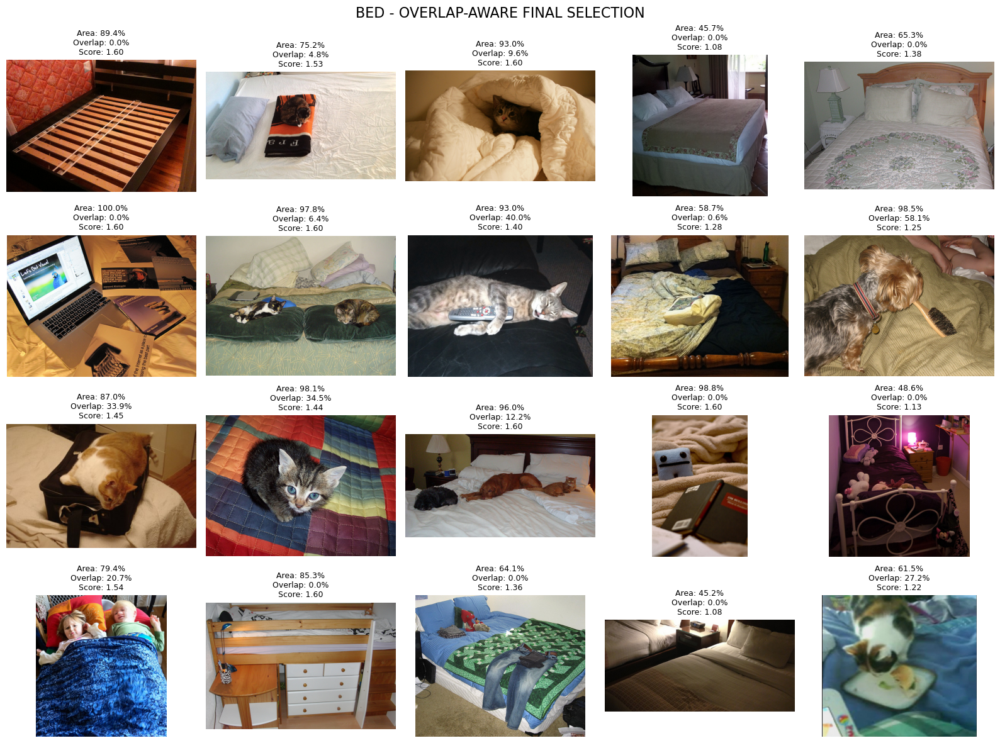

In [11]:
# STEP 7D: VISUAL CHECK OF OVERLAP-AWARE BED SELECTION

import matplotlib.pyplot as plt
import random

random.seed(123)

class_name = "bed"
samples = random.sample(
    clean_selected_candidates[class_name],
    20
)

fig, axes = plt.subplots(
    4, 5,
    figsize=(16, 12)
)

fig.suptitle(
    "BED - OVERLAP-AWARE FINAL SELECTION",
    fontsize=16
)

for ax, item in zip(axes.flat, samples):

    img = item["image"]

    x1, y1, x2, y2 = item["bbox"]

    crop = img.crop((
        int(x1),
        int(y1),
        int(x2),
        int(y2)
    ))

    ax.imshow(crop)

    ax.set_title(
        f"Area: {item['area_ratio']*100:.1f}%\n"
        f"Overlap: {item['max_competing_overlap']*100:.1f}%\n"
        f"Score: {item['quality_score']:.2f}",
        fontsize=9
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [12]:
# STEP 7E: ANALYZE CLEANER BED CANDIDATES

bed_candidates = clean_selected_candidates["bed"]

thresholds = [0.00, 0.05, 0.10, 0.15, 0.20]

print("=" * 70)
print("🛏️ BED OVERLAP THRESHOLD ANALYSIS")
print("=" * 70)

for threshold in thresholds:

    clean = [
        item
        for item in bed_candidates
        if item["max_competing_overlap"] <= threshold
    ]

    print(
        f"Overlap <= {threshold*100:4.0f}% : "
        f"{len(clean):3d}/100 images"
    )

print("=" * 70)


# Also check the FULL 250-candidate pool,
# because there may be cleaner beds that were not selected.

print("\nFULL BED CANDIDATE POOL:")

for threshold in thresholds:

    count = 0

    for item in class_candidates["bed"]:

        target_box = item["bbox"]

        tx1, ty1, tx2, ty2 = target_box

        target_area = max(
            (tx2 - tx1) * (ty2 - ty1),
            1
        )

        max_overlap = 0.0

        for other_box, other_cat in zip(
            item["annotations"]["bbox"],
            item["annotations"]["category"]
        ):

            if other_cat == SELECTED_CLASSES["bed"]:
                continue

            if other_cat not in id_to_name:
                continue

            overlap = intersection_area(
                target_box,
                other_box
            )

            max_overlap = max(
                max_overlap,
                overlap / target_area
            )

        if max_overlap <= threshold:
            count += 1

    print(
        f"Overlap <= {threshold*100:4.0f}% : "
        f"{count:3d}/250 candidates"
    )

print("=" * 70)

🛏️ BED OVERLAP THRESHOLD ANALYSIS
Overlap <=    0% :  36/100 images
Overlap <=    5% :  50/100 images
Overlap <=   10% :  58/100 images
Overlap <=   15% :  64/100 images
Overlap <=   20% :  65/100 images

FULL BED CANDIDATE POOL:
Overlap <=    0% : 106/250 candidates
Overlap <=    5% : 137/250 candidates
Overlap <=   10% : 151/250 candidates
Overlap <=   15% : 161/250 candidates
Overlap <=   20% : 167/250 candidates


In [13]:
# STEP 7F: RESELECT CLEAN BED SAMPLES FROM FULL 250-CANDIDATE POOL

class_name = "bed"

bed_scored = []

for item in class_candidates[class_name]:

    area = item["area_ratio"]
    bw = item["bbox_width"]
    bh = item["bbox_height"]

    # --------------------------------
    # Quality score
    # --------------------------------

    median_area = np.median([
        x["area_ratio"]
        for x in class_candidates[class_name]
    ])

    area_score = min(
        area / max(median_area, 1e-8),
        2.0
    )

    resolution_score = min(
        min(bw, bh) / 100.0,
        1.0
    )

    aspect_ratio = (
        max(bw, bh) /
        max(min(bw, bh), 1)
    )

    if aspect_ratio <= 4:
        aspect_score = 1.0
    elif aspect_ratio <= 6:
        aspect_score = 0.8
    else:
        aspect_score = 0.5

    base_score = (
        0.60 * area_score +
        0.30 * resolution_score +
        0.10 * aspect_score
    )

    # --------------------------------
    # Calculate competing overlap
    # --------------------------------

    target_box = item["bbox"]

    tx1, ty1, tx2, ty2 = target_box

    target_area = max(
        (tx2 - tx1) * (ty2 - ty1),
        1
    )

    max_overlap = 0.0

    for other_box, other_cat in zip(
        item["annotations"]["bbox"],
        item["annotations"]["category"]
    ):

        if other_cat == SELECTED_CLASSES[class_name]:
            continue

        if other_cat not in id_to_name:
            continue

        overlap = intersection_area(
            target_box,
            other_box
        )

        overlap_ratio = overlap / target_area

        max_overlap = max(
            max_overlap,
            overlap_ratio
        )

    candidate = item.copy()

    candidate["base_score"] = base_score
    candidate["max_competing_overlap"] = max_overlap
    candidate["quality_score"] = base_score

    bed_scored.append(candidate)


# --------------------------------
# STRICT BED FILTER
# --------------------------------

clean_bed_pool = [
    item
    for item in bed_scored
    if item["max_competing_overlap"] <= 0.10
]

clean_bed_pool.sort(
    key=lambda x: x["quality_score"],
    reverse=True
)

new_bed_selection = clean_bed_pool[:100]

# Replace ONLY bed
clean_selected_candidates["bed"] = new_bed_selection


# --------------------------------
# Report
# --------------------------------

print("=" * 70)
print("🛏️ CLEAN BED RESELECTION COMPLETE")
print("=" * 70)

print("Clean candidates available:", len(clean_bed_pool))
print("Selected:", len(new_bed_selection))

print(
    "Maximum competing overlap:",
    f"{max(x['max_competing_overlap'] for x in new_bed_selection)*100:.2f}%"
)

print(
    "Median competing overlap:",
    f"{np.median([x['max_competing_overlap'] for x in new_bed_selection])*100:.2f}%"
)

print(
    "Area range:",
    f"{min(x['area_ratio'] for x in new_bed_selection)*100:.2f}% - "
    f"{max(x['area_ratio'] for x in new_bed_selection)*100:.2f}%"
)

print("=" * 70)

🛏️ CLEAN BED RESELECTION COMPLETE
Clean candidates available: 151
Selected: 100
Maximum competing overlap: 9.61%
Median competing overlap: 0.00%
Area range: 20.87% - 99.98%


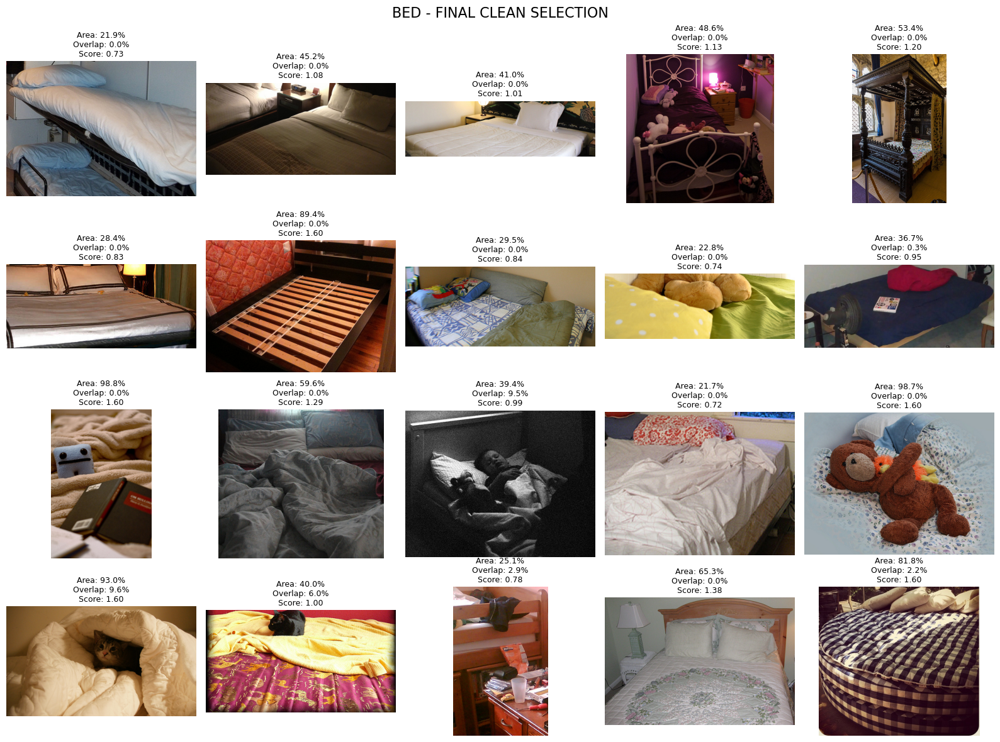

In [14]:
# STEP 7G: FINAL VISUAL CHECK OF CLEAN BED SELECTION

import matplotlib.pyplot as plt
import random

random.seed(456)

samples = random.sample(
    clean_selected_candidates["bed"],
    20
)

fig, axes = plt.subplots(
    4, 5,
    figsize=(16, 12)
)

fig.suptitle(
    "BED - FINAL CLEAN SELECTION",
    fontsize=16
)

for ax, item in zip(axes.flat, samples):

    img = item["image"]

    x1, y1, x2, y2 = item["bbox"]

    crop = img.crop((
        int(x1),
        int(y1),
        int(x2),
        int(y2)
    ))

    ax.imshow(crop)

    ax.set_title(
        f"Area: {item['area_ratio']*100:.1f}%\n"
        f"Overlap: {item['max_competing_overlap']*100:.1f}%\n"
        f"Score: {item['quality_score']:.2f}",
        fontsize=9
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [15]:
# STEP 8: CREATE FINAL 70 / 15 / 15 SPLIT

import random

random.seed(42)

train_data = {}
val_data = {}
test_data = {}

print("=" * 75)
print("📂 CREATING FINAL CLASSIFICATION SPLIT")
print("=" * 75)

for class_name in SELECTED_CLASSES:

    items = clean_selected_candidates[class_name].copy()

    # Deterministic random shuffle
    random.shuffle(items)

    # Exactly 100 images per class
    assert len(items) == 100, (
        f"{class_name} has {len(items)} images instead of 100"
    )

    train_data[class_name] = items[:70]
    val_data[class_name]   = items[70:85]
    test_data[class_name]  = items[85:100]

    print(
        f"✅ {class_name:20s} | "
        f"Train: {len(train_data[class_name]):2d} | "
        f"Val: {len(val_data[class_name]):2d} | "
        f"Test: {len(test_data[class_name]):2d}"
    )

print("=" * 75)

train_total = sum(len(v) for v in train_data.values())
val_total   = sum(len(v) for v in val_data.values())
test_total  = sum(len(v) for v in test_data.values())

print(f"Train total : {train_total}")
print(f"Val total   : {val_total}")
print(f"Test total  : {test_total}")
print(f"Grand total : {train_total + val_total + test_total}")

print("=" * 75)

📂 CREATING FINAL CLASSIFICATION SPLIT
✅ person               | Train: 70 | Val: 15 | Test: 15
✅ bicycle              | Train: 70 | Val: 15 | Test: 15
✅ car                  | Train: 70 | Val: 15 | Test: 15
✅ motorcycle           | Train: 70 | Val: 15 | Test: 15
✅ airplane             | Train: 70 | Val: 15 | Test: 15
✅ bus                  | Train: 70 | Val: 15 | Test: 15
✅ train                | Train: 70 | Val: 15 | Test: 15
✅ truck                | Train: 70 | Val: 15 | Test: 15
✅ traffic light        | Train: 70 | Val: 15 | Test: 15
✅ stop sign            | Train: 70 | Val: 15 | Test: 15
✅ bench                | Train: 70 | Val: 15 | Test: 15
✅ bird                 | Train: 70 | Val: 15 | Test: 15
✅ cat                  | Train: 70 | Val: 15 | Test: 15
✅ dog                  | Train: 70 | Val: 15 | Test: 15
✅ horse                | Train: 70 | Val: 15 | Test: 15
✅ cow                  | Train: 70 | Val: 15 | Test: 15
✅ elephant             | Train: 70 | Val: 15 | Test: 15
✅ bottle  

In [16]:
# STEP 8A-1: INSPECT STORED CANDIDATE FIELDS

sample = train_data["person"][0]

print("Available keys:")
print(sample.keys())

print("\nStored values:")
for key in sample.keys():
    if key not in ["image", "annotations"]:
        print(f"{key}: {sample[key]}")

Available keys:
dict_keys(['image', 'annotations', 'bbox', 'class_name', 'class_id', 'source_idx', 'image_width', 'image_height', 'bbox_width', 'bbox_height', 'bbox_area', 'area_ratio', 'base_score', 'max_competing_overlap', 'quality_score'])

Stored values:
bbox: [331.44, 35.53, 470.35, 555.38]
class_name: person
class_id: 0
source_idx: 183
image_width: 612
image_height: 612
bbox_width: 138.91000000000003
bbox_height: 519.85
bbox_area: 72212.36350000002
area_ratio: 0.19280074837669278
base_score: 1.6
max_competing_overlap: 0.0
quality_score: 1.6


In [17]:
# STEP 8A: CHECK SOURCE-IMAGE LEAKAGE BETWEEN SPLITS

def get_source_ids(split_data):
    ids = set()

    for class_name in split_data:
        for item in split_data[class_name]:

            # Original COCO source-image index
            ids.add(item["source_idx"])

    return ids


train_ids = get_source_ids(train_data)
val_ids   = get_source_ids(val_data)
test_ids  = get_source_ids(test_data)


train_val_overlap  = train_ids & val_ids
train_test_overlap = train_ids & test_ids
val_test_overlap   = val_ids & test_ids


print("=" * 70)
print("🔍 SOURCE-IMAGE LEAKAGE CHECK")
print("=" * 70)

print("Unique source images:")
print("Train :", len(train_ids))
print("Val   :", len(val_ids))
print("Test  :", len(test_ids))

print()

print("Train ↔ Val overlap :", len(train_val_overlap))
print("Train ↔ Test overlap:", len(train_test_overlap))
print("Val ↔ Test overlap  :", len(val_test_overlap))

print("=" * 70)

if (
    len(train_val_overlap) == 0
    and len(train_test_overlap) == 0
    and len(val_test_overlap) == 0
):
    print("No source-image leakage detected.")
else:
    print("Source-image leakage detected.")
    print("Fix the split before saving.")

🔍 SOURCE-IMAGE LEAKAGE CHECK
Unique source images:
Train : 1470
Val   : 357
Test  : 354

Train ↔ Val overlap : 103
Train ↔ Test overlap: 82
Val ↔ Test overlap  : 14
Source-image leakage detected.
Fix the split before saving.


In [18]:
# STEP 8B: CREATE LEAKAGE-FREE 70 / 15 / 15 SPLIT

import random
from collections import defaultdict

random.seed(42)

TARGET = {
    "train": 70,
    "val": 15,
    "test": 15
}

# ---------------------------------------------------------
# Group all selected classification objects by source image
# ---------------------------------------------------------

source_groups = defaultdict(list)

for class_name in SELECTED_CLASSES:
    for item in clean_selected_candidates[class_name]:
        source_groups[item["source_idx"]].append(
            (class_name, item)
        )

print("Unique source images:", len(source_groups))


# ---------------------------------------------------------
# Sort groups:
# multi-class source images first because they are harder
# to place without breaking class quotas.
# ---------------------------------------------------------

groups = list(source_groups.items())

random.shuffle(groups)

groups.sort(
    key=lambda x: len(x[1]),
    reverse=True
)


# ---------------------------------------------------------
# Initialize final split
# ---------------------------------------------------------

final_split = {
    "train": defaultdict(list),
    "val": defaultdict(list),
    "test": defaultdict(list)
}


def can_place(group_items, split_name):
    """
    Check whether placing this entire source image
    would exceed any class quota.
    """

    class_counts = defaultdict(int)

    for class_name, _ in group_items:
        class_counts[class_name] += 1

    for class_name, amount in class_counts.items():

        current = len(
            final_split[split_name][class_name]
        )

        if current + amount > TARGET[split_name]:
            return False

    return True


# ---------------------------------------------------------
# Place complete source groups
# ---------------------------------------------------------

unplaced_groups = []

for source_idx, group_items in groups:

    possible = []

    for split_name in ["train", "val", "test"]:

        if can_place(group_items, split_name):

            # Calculate how much this placement helps
            # fill currently missing class slots.
            need_score = 0

            for class_name, _ in group_items:

                remaining = (
                    TARGET[split_name]
                    - len(final_split[split_name][class_name])
                )

                need_score += (
                    remaining / TARGET[split_name]
                )

            possible.append(
                (need_score, split_name)
            )

    if not possible:
        unplaced_groups.append(
            (source_idx, group_items)
        )
        continue

    # Highest need first
    possible.sort(reverse=True)

    chosen_split = possible[0][1]

    for class_name, item in group_items:
        final_split[chosen_split][class_name].append(item)


# ---------------------------------------------------------
# Report
# ---------------------------------------------------------

print("\n" + "=" * 78)
print("📊 GROUPED SPLIT RESULTS")
print("=" * 78)

all_exact = True

for class_name in SELECTED_CLASSES:

    tr = len(final_split["train"][class_name])
    va = len(final_split["val"][class_name])
    te = len(final_split["test"][class_name])

    exact = (
        tr == 70 and
        va == 15 and
        te == 15
    )

    if not exact:
        all_exact = False

    status = "✅" if exact else "⚠️"

    print(
        f"{status} {class_name:20s} | "
        f"Train {tr:2d} | "
        f"Val {va:2d} | "
        f"Test {te:2d}"
    )

print("=" * 78)

print("Unplaced source groups:", len(unplaced_groups))

if all_exact and len(unplaced_groups) == 0:
    print("✅ Exact leakage-free 70/15/15 split achieved.")
else:
    print("⚠️ Exact split not achieved yet.")
    print("This is expected if source groups conflict with exact quotas.")

Unique source images: 1989

📊 GROUPED SPLIT RESULTS
✅ person               | Train 70 | Val 15 | Test 15
✅ bicycle              | Train 70 | Val 15 | Test 15
✅ car                  | Train 70 | Val 15 | Test 15
✅ motorcycle           | Train 70 | Val 15 | Test 15
✅ airplane             | Train 70 | Val 15 | Test 15
✅ bus                  | Train 70 | Val 15 | Test 15
✅ train                | Train 70 | Val 15 | Test 15
✅ truck                | Train 70 | Val 15 | Test 15
✅ traffic light        | Train 70 | Val 15 | Test 15
✅ stop sign            | Train 70 | Val 15 | Test 15
✅ bench                | Train 70 | Val 15 | Test 15
✅ bird                 | Train 70 | Val 15 | Test 15
✅ cat                  | Train 70 | Val 15 | Test 15
✅ dog                  | Train 70 | Val 15 | Test 15
✅ horse                | Train 70 | Val 15 | Test 15
✅ cow                  | Train 70 | Val 15 | Test 15
✅ elephant             | Train 70 | Val 15 | Test 15
✅ bottle               | Train 70 | Val 15 | Te

In [19]:
# STEP 8C: FINALIZE + VERIFY LEAKAGE-FREE SPLIT

train_data = {
    class_name: list(final_split["train"][class_name])
    for class_name in SELECTED_CLASSES
}

val_data = {
    class_name: list(final_split["val"][class_name])
    for class_name in SELECTED_CLASSES
}

test_data = {
    class_name: list(final_split["test"][class_name])
    for class_name in SELECTED_CLASSES
}


# ---------------------------------------------------------
# Count samples
# ---------------------------------------------------------

train_total = sum(len(v) for v in train_data.values())
val_total   = sum(len(v) for v in val_data.values())
test_total  = sum(len(v) for v in test_data.values())


# ---------------------------------------------------------
# Get source-image IDs
# ---------------------------------------------------------

def get_source_ids(split_data):
    return {
        item["source_idx"]
        for items in split_data.values()
        for item in items
    }


train_ids = get_source_ids(train_data)
val_ids   = get_source_ids(val_data)
test_ids  = get_source_ids(test_data)


# ---------------------------------------------------------
# Final verification
# ---------------------------------------------------------

print("=" * 70)
print("✅ FINAL SPLIT VERIFICATION")
print("=" * 70)

print(f"Train samples : {train_total}")
print(f"Val samples   : {val_total}")
print(f"Test samples  : {test_total}")
print(f"Total samples : {train_total + val_total + test_total}")

print()

print(f"Unique Train source images : {len(train_ids)}")
print(f"Unique Val source images   : {len(val_ids)}")
print(f"Unique Test source images  : {len(test_ids)}")

print()

print("Train ↔ Val leakage :", len(train_ids & val_ids))
print("Train ↔ Test leakage:", len(train_ids & test_ids))
print("Val ↔ Test leakage  :", len(val_ids & test_ids))

print("=" * 70)

assert train_total == 1750
assert val_total == 375
assert test_total == 375

assert len(train_ids & val_ids) == 0
assert len(train_ids & test_ids) == 0
assert len(val_ids & test_ids) == 0

print("🎯 FINAL CLASSIFICATION SPLIT IS VALID.")


✅ FINAL SPLIT VERIFICATION
Train samples : 1750
Val samples   : 375
Test samples  : 375
Total samples : 2500

Unique Train source images : 1410
Unique Val source images   : 283
Unique Test source images  : 296

Train ↔ Val leakage : 0
Train ↔ Test leakage: 0
Val ↔ Test leakage  : 0
🎯 FINAL CLASSIFICATION SPLIT IS VALID.


In [20]:
# STEP 9A: CREATE FINAL CLASSIFICATION DIRECTORY STRUCTURE

import os

CLASSIFICATION_DIR = os.path.join(BASE_DIR, "classification")

splits = ["train", "val", "test"]

print("=" * 70)
print("📁 CREATING FINAL CLASSIFICATION FOLDERS")
print("=" * 70)

for split in splits:
    for class_name in SELECTED_CLASSES:

        class_dir = os.path.join(
            CLASSIFICATION_DIR,
            split,
            class_name
        )

        os.makedirs(class_dir, exist_ok=True)

print("✅ Directory structure created successfully.")

print("\nClassification directory:")
print(CLASSIFICATION_DIR)

print("\nExpected structure:")
print("classification/")
print("├── train/  → 25 class folders")
print("├── val/    → 25 class folders")
print("└── test/   → 25 class folders")

print("=" * 70)

📁 CREATING FINAL CLASSIFICATION FOLDERS
✅ Directory structure created successfully.

Classification directory:
E:\SmartVision-AI\data\final_dataset\classification

Expected structure:
classification/
├── train/  → 25 class folders
├── val/    → 25 class folders
└── test/   → 25 class folders


In [ ]:
# STEP 9B: SAVE FINAL CLASSIFICATION CROPS
# Correct bbox format: XYXY

import os
from PIL import Image

IMAGE_SIZE = (224, 224)

split_data = {
    "train": train_data,
    "val": val_data,
    "test": test_data
}

saved_counts = {
    "train": 0,
    "val": 0,
    "test": 0
}

print("=" * 75)
print("💾 SAVING FINAL CLASSIFICATION DATASET")
print("=" * 75)

for split_name, data in split_data.items():

    print(f"\nProcessing {split_name.upper()}...")

    for class_name in SELECTED_CLASSES:

        class_dir = os.path.join(
            CLASSIFICATION_DIR,
            split_name,
            class_name
        )

        items = data[class_name]

        for i, item in enumerate(items):

            # Original image
            img = item["image"].convert("RGB")

            # Correct COCO bbox format for this dataset: XYXY
            x1, y1, x2, y2 = item["bbox"]

            # Clip coordinates to image boundaries
            x1 = max(0, int(round(x1)))
            y1 = max(0, int(round(y1)))
            x2 = min(img.width, int(round(x2)))
            y2 = min(img.height, int(round(y2)))

            # Safety check
            if x2 <= x1 or y2 <= y1:
                raise ValueError(
                    f"Invalid bbox for {class_name}: "
                    f"{item['bbox']}"
                )

            # Crop target object
            crop = img.crop((x1, y1, x2, y2))

            # Resize to required classification input size
            crop = crop.resize(
                IMAGE_SIZE,
                Image.Resampling.LANCZOS
            )

            # Safe filename
            safe_class = class_name.replace(" ", "_")

            filename = (
                f"{safe_class}_"
                f"{item['source_idx']:06d}_"
                f"{i:03d}.jpg"
            )

            save_path = os.path.join(
                class_dir,
                filename
            )

            crop.save(
                save_path,
                format="JPEG",
                quality=95
            )

            saved_counts[split_name] += 1

        print(
            f"✅ {class_name:20s} "
            f"{len(items):3d} images"
        )


print("\n" + "=" * 75)
print("📊 SAVING COMPLETE")
print("=" * 75)

print("Train :", saved_counts["train"])
print("Val   :", saved_counts["val"])
print("Test  :", saved_counts["test"])

total_saved = sum(saved_counts.values())

print("Total :", total_saved)

assert saved_counts["train"] == 1750
assert saved_counts["val"] == 375
assert saved_counts["test"] == 375
assert total_saved == 2500

print("\n🎯 ALL 2,500 CLASSIFICATION IMAGES SAVED SUCCESSFULLY.")
print("=" * 75)

💾 SAVING FINAL CLASSIFICATION DATASET

Processing TRAIN...
✅ person                70 images
✅ bicycle               70 images
✅ car                   70 images
✅ motorcycle            70 images
✅ airplane              70 images
✅ bus                   70 images
✅ train                 70 images
✅ truck                 70 images
✅ traffic light         70 images
✅ stop sign             70 images
✅ bench                 70 images
✅ bird                  70 images
✅ cat                   70 images
✅ dog                   70 images
✅ horse                 70 images
✅ cow                   70 images
✅ elephant              70 images
✅ bottle                70 images
✅ cup                   70 images
✅ bowl                  70 images
✅ pizza                 70 images
✅ cake                  70 images
✅ chair                 70 images


In [22]:
# STEP 9C: VALIDATE SAVED CLASSIFICATION DATASET

import os
from PIL import Image

expected_counts = {
    "train": 70,
    "val": 15,
    "test": 15
}

total_files = 0
corrupted_files = []
wrong_size = []
wrong_mode = []
count_errors = []

print("=" * 75)
print("🔍 VALIDATING SAVED CLASSIFICATION DATASET")
print("=" * 75)

for split in ["train", "val", "test"]:

    split_total = 0

    for class_name in SELECTED_CLASSES:

        class_dir = os.path.join(
            CLASSIFICATION_DIR,
            split,
            class_name
        )

        files = [
            f for f in os.listdir(class_dir)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        # Check class count
        if len(files) != expected_counts[split]:
            count_errors.append(
                (split, class_name, len(files))
            )

        split_total += len(files)

        # Check every saved image
        for filename in files:

            path = os.path.join(class_dir, filename)

            try:
                with Image.open(path) as img:

                    if img.size != (224, 224):
                        wrong_size.append(
                            (path, img.size)
                        )

                    if img.mode != "RGB":
                        wrong_mode.append(
                            (path, img.mode)
                        )

                    img.verify()

            except Exception as e:
                corrupted_files.append(
                    (path, str(e))
                )

    total_files += split_total

    print(
        f"{split.upper():5s} : "
        f"{split_total} files"
    )


print("\n" + "=" * 75)
print("📊 VALIDATION RESULTS")
print("=" * 75)

print("Total files       :", total_files)
print("Count errors      :", len(count_errors))
print("Corrupted files   :", len(corrupted_files))
print("Wrong dimensions  :", len(wrong_size))
print("Wrong color mode  :", len(wrong_mode))

print("=" * 75)

if (
    total_files == 2500
    and len(count_errors) == 0
    and len(corrupted_files) == 0
    and len(wrong_size) == 0
    and len(wrong_mode) == 0
):
    print("🎯 DATASET VALIDATION PASSED.")
else:
    print("⚠️ Dataset validation found problems.")

TEST  : 375 files

📊 VALIDATION RESULTS
Total files       : 2500
Count errors      : 0
Corrupted files   : 0
Wrong dimensions  : 0
Wrong color mode  : 0
🎯 DATASET VALIDATION PASSED.


In [ ]:
# STEP 9D: VISUAL QA OF ACTUAL SAVED DATASET

import os
import random
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)

# Show 2 random TRAIN images from every class
samples_per_class = 2

fig, axes = plt.subplots(
    len(SELECTED_CLASSES),
    samples_per_class,
    figsize=(8, 3 * len(SELECTED_CLASSES))
)

for row, class_name in enumerate(SELECTED_CLASSES):

    class_dir = os.path.join(
        CLASSIFICATION_DIR,
        "train",
        class_name
    )

    files = [
        f for f in os.listdir(class_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    selected_files = random.sample(
        files,
        samples_per_class
    )

    for col, filename in enumerate(selected_files):

        path = os.path.join(
            class_dir,
            filename
        )

        img = Image.open(path)

        axes[row, col].imshow(img)
        axes[row, col].axis("off")

        axes[row, col].set_title(
            f"{class_name}\n{filename}",
            fontsize=8
        )

plt.tight_layout()
plt.show()